# 11장 원인 상태의 추정 (실습)

9장의 캡슐은 사전 μv 를 위에서 받은 값 그대로 썼다. 이번 캡슐(버전 0.6)은 원인 상태 μ̃v 도 숨은 상태처럼 경사 하강으로 추정하고, 위에서 내려온 사전은 μ̃v 에 대한 또 하나의 예측 오차 ε̃v = μ̃v − 사전 으로 들어간다. 생성 과정은 강화 학습의 Gym 과 같은 reset/step 인터페이스의 환경 클래스로 감싼다.

1. 환경 클래스와 캡슐 버전 0.6
2. 첫 실험: 9장과 같은 조건
3. 숨은 상태는 실제를, 원인 상태는 사전을 — 편향 없는 믿음으로도 행동이 나오는가
4. 유색 잡음 속에서
5. 세 정밀도(감각, 사전, 숨은 상태)의 여덟 조합
6. 움직이는 사전을 따라가기 — 생성 모델의 시간 상수

실패 조건은 사전을 믿지 않고 숨은 상태만 믿는 조합이다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv
from scipy.signal.windows import gaussian

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

def _e(x): return np.exp(5 - x / 5)
def g_gp(x):   return 25 - 16 / (1 + _e(x))
def dg_gp(x):  return -16 / 5 * _e(x) / (1 + _e(x))**2
def ddg_gp(x): e = _e(x); return -16 / 25 * e * (e - 1) / (1 + e)**3

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

def timeline(T, dt=0.005):
    return np.arange(0, T + dt / 2, dt)

print("준비 완료")

준비 완료


## 1. Gym 형식의 환경

생성 과정을 클래스 하나로 감싼다. reset 은 처음 깊이로 되돌리고 첫 감각을 돌려준다. step 은 행동 u 를 받아 한 걸음 진행하고 일반화 감각 ỹ 를 돌려준다. 보상은 없고 종료 신호도 쓰지 않는다. 시뮬레이션 길이는 시간 축이 정한다.

In [2]:
class HydarEnv:
    """Hydar 의 생성 과정: x′ = u + w, y = g_gp(x) + z. Gym 처럼 reset/step 을 쓴다."""

    def __init__(self, t, p, s2_w=0.1, s2_z=0.1, noise="none", seed=42):
        self.t, self.dt, self.p, self.noise = t, t[1] - t[0], p, noise
        np.random.seed(seed)
        self.s2 = 1 / 2000
        self.w = makeNoise(s2_w, self.s2, t)[0] if noise == "smooth" else np.zeros(t.size)
        self.z = makeNoise(s2_z, self.s2, t)[0] if noise == "smooth" else np.zeros(t.size)

    def _observe(self, xd):
        x = self.x
        full = [g_gp(x) + self.z[self.i], dg_gp(x) * xd, ddg_gp(x) * xd**2]   # 정확한 일반화 감각
        return np.array(full[:self.p + 1]).reshape(-1, 1)

    def reset(self, x_init):
        self.i, self.x = 0, x_init
        return self._observe(0.0)

    def step(self, u):
        self.i += 1
        xd = u + self.w[self.i]
        self.x += self.dt * xd
        return self._observe(xd)

env = HydarEnv(timeline(1.0), p=2)
y0 = env.reset(30.0)
print("reset 감각 ỹ =", np.round(y0.ravel(), 3), "  step(u=−2) 감각 ỹ =", np.round(env.step(-2.0).ravel(), 3))

reset 감각 ỹ = [13.303 -0.     0.   ]   step(u=−2) 감각 ỹ = [13.309  1.259  0.232]


## 2. 캡슐 버전 0.6 — 원인 상태 추정

생성 모델: Dμ̃x = f̃(μ̃x, μ̃v) + w̃, ỹ = g̃(μ̃x) + z̃, μ̃v = 사전 + ṽ. f = −μx + μv, g 는 시그모이드.

- ε̃x = Dμ̃x − f̃,  ε̃y = ỹ − g̃,  ε̃v = μ̃v − 사전
- μ̃̇x = Dμ̃x − αx[(D + I)ᵀ Π̃x ε̃x − g′ Π̃y ε̃y]
- μ̃̇v = Dμ̃v − αv[−Π̃x ε̃x + Π̃v ε̃v]   (∂f/∂μv = 1, g 는 μv 에 무관)
- u̇ = −αu (∂ỹ/∂u)ᵀ Π̃y ε̃y

In [3]:
class ai_capsule:
    """숨은 상태와 원인 상태를 함께 추정하고 행동하는 뉴런 묶음 (버전 0.6)."""

    def __init__(self, dt, x0, v0, p, s2_x, s2_y, s2_v, a_x, a_v, a_u, s2=1 / 64, a=-1.0):
        self.dt, self.p, self.a = dt, p, a
        self.a_x, self.a_v, self.a_u = a_x, a_v, a_u
        self.I, self.D = np.eye(p + 1), derivativeD(p)
        self.e0 = self.I[:, :1]
        self.mu_x = self.e0 * x0
        self.mu_v = self.e0 * v0
        self.u = 0.0
        S = temporalC(p, s2)
        self.Pi_x, self.Pi_y, self.Pi_v = (inv(np.kron(S, s)) for s in (s2_x, s2_y, s2_v))

    def ai_step(self, prior, y, act):
        mx, mv = self.mu_x, self.mu_v
        g1 = dg_gp(mx[0, 0])
        f_t = self.a * mx + (-self.a) * mv                           # f = a μx − a μv (a = −1 이면 −μx + μv)
        g_t = self.e0 * g_gp(mx[0, 0]) + (1 - self.e0) * g1 * mx
        eps_x = self.D @ mx - f_t
        eps_y = y - g_t
        eps_v = mv - self.e0 * prior
        F = 0.5 * (eps_x.T @ self.Pi_x @ eps_x + eps_y.T @ self.Pi_y @ eps_y + eps_v.T @ self.Pi_v @ eps_v).item()
        dF_x = (self.D - self.a * self.I).T @ self.Pi_x @ eps_x - g1 * self.Pi_y @ eps_y
        dF_v = (self.a * self.I).T @ self.Pi_x @ eps_x + self.Pi_v @ eps_v
        self.mu_x = mx + self.dt * (self.D @ mx - self.a_x * dF_x)
        self.mu_v = mv + self.dt * (self.D @ mv - self.a_v * dF_v)
        if act:
            fwd = np.zeros((self.p + 1, 1)); fwd[1] = g1                 # 정확한 전방 모델 [0, g′, …]
            self.u += self.dt * -self.a_u * (fwd.T @ self.Pi_y @ eps_y).item()
        return self.u, F


def run(prior, x_init=30.0, T=10.0, s2_x=0.1, s2_y=0.1, s2_v=0.1, a_x=1.0, a_v=1.0, a_u=50.0,
        p=1, noise="none", t_act=2.0, a=-1.0):
    t = timeline(T)
    prior = np.broadcast_to(prior, t.shape).astype(float)
    env = HydarEnv(t, p, noise=noise, s2_w=s2_x, s2_z=s2_y)
    y = env.reset(x_init)
    cap = ai_capsule(t[1] - t[0], prior[0], prior[0], p, s2_x, s2_y, s2_v, a_x, a_v, a_u,
                     s2=1 / 2000 if noise == "smooth" else 1 / 64, a=a)
    rec = {k: np.zeros(t.size) for k in ["x", "y", "mx", "mx1", "mv", "u", "F"]}
    rec["x"][0], rec["y"][0], rec["mx"][0], rec["mv"][0] = x_init, y[0, 0], prior[0], prior[0]
    u = 0.0
    with np.errstate(all="ignore"):
        for i in range(1, t.size):
            y = env.step(u)
            u, F = cap.ai_step(prior[i], y, t[i] > t_act)
            rec["x"][i], rec["y"][i], rec["mx"][i], rec["mv"][i], rec["u"][i], rec["F"][i] = \
                env.x, y[0, 0], cap.mu_x[0, 0], cap.mu_v[0, 0], u, F
            rec["mx1"][i] = cap.mu_x[1, 0]                               # 믿음의 속도 μx′
    rec["t"], rec["prior"] = t, prior
    return rec

def at(r, sec):
    return min(int(round(sec / (r["t"][1] - r["t"][0]))), r["t"].size - 1)

def arrival(r, target=25.0, tol=0.5):
    bad = np.where(np.abs(r["x"] - target) >= tol)[0]
    return r["t"][bad[-1] + 1] if bad.size and bad[-1] + 1 < r["t"].size else (np.inf if bad.size else 0.0)

print("ai_capsule v0.6, run 준비 완료")

ai_capsule v0.6, run 준비 완료


## 3. 첫 실험 — 9장과 같은 조건

Hydar 는 깊이 30 에서 출발하고 사전은 25 다. 세 분산 모두 0.1, 학습률 αx = αv = 1, αu = 50, p = 1, 잡음 없음, 행동은 2 초부터.

In [4]:
r1 = run(25.0)
print(" 시간    깊이    μx      μv      행동")
for sec in [1.99, 2.5, 3, 4, 6, 10]:
    k = at(r1, sec)
    print(f"{sec:5.2f}s  {r1['x'][k]:6.2f}  {r1['mx'][k]:6.2f}  {r1['mv'][k]:6.3f}  {r1['u'][k]:+6.2f}")
k_min = np.argmin(r1["mv"])
print(f"μv 의 최솟값 {r1['mv'][k_min]:.3f} ({r1['t'][k_min]:.2f}s),  도착 {arrival(r1):.2f}s")

 시간    깊이    μx      μv      행동
 1.99s   30.00   28.86  25.044   +0.00
 2.50s   28.59   28.36  24.870   -3.65
 3.00s   26.93   27.18  24.701   -2.86
 4.00s   25.09   25.36  24.730   -0.92
 6.00s   24.78   24.80  24.949   +0.13
10.00s   24.99   24.99  24.998   +0.01
μv 의 최솟값 24.673 (3.35s),  도착 3.66s


## 4. 숨은 상태는 실제를, 원인 상태는 사전을

숨은 상태의 분산을 크게(σx² = 5), 감각과 사전의 분산을 작게(0.1) 둔다. 원본의 설정대로 αx = 8, αv = 3, αu = 150, p = 2 다. 기준(세 분산 모두 0.1, 같은 학습률)과 비교한다.

In [5]:
cases = {"9장 설정 (p=1, 분산 0.1, 학습률 1)": dict(p=1, s2_x=0.1, a_x=1, a_v=1, a_u=50),
         "원본 설정 (p=2, σx²=5, αx 8, αv 3)": dict(p=2, s2_x=5.0, a_x=8, a_v=3, a_u=150)}
r_unb = {}
print("경우                                 2초 깊이   2초 μx    2초 μx′    2초 μv    도착     10초 깊이")
for name, kw in cases.items():
    r = run(25.0, **kw)
    r_unb[name] = r
    k = at(r, 1.99)
    print(f"{name:32s}   {r['x'][k]:6.2f}   {r['mx'][k]:6.2f}   {r['mx1'][k]:+6.2f}   {r['mv'][k]:6.3f}   {arrival(r):5.2f}s   {r['x'][-1]:6.3f}")

경우                                 2초 깊이   2초 μx    2초 μx′    2초 μv    도착     10초 깊이
9장 설정 (p=1, 분산 0.1, 학습률 1)          30.00    28.86    -3.67   25.044    3.66s   24.993
원본 설정 (p=2, σx²=5, αx 8, αv 3)      30.00    29.85    -3.25   25.030    3.68s   25.159


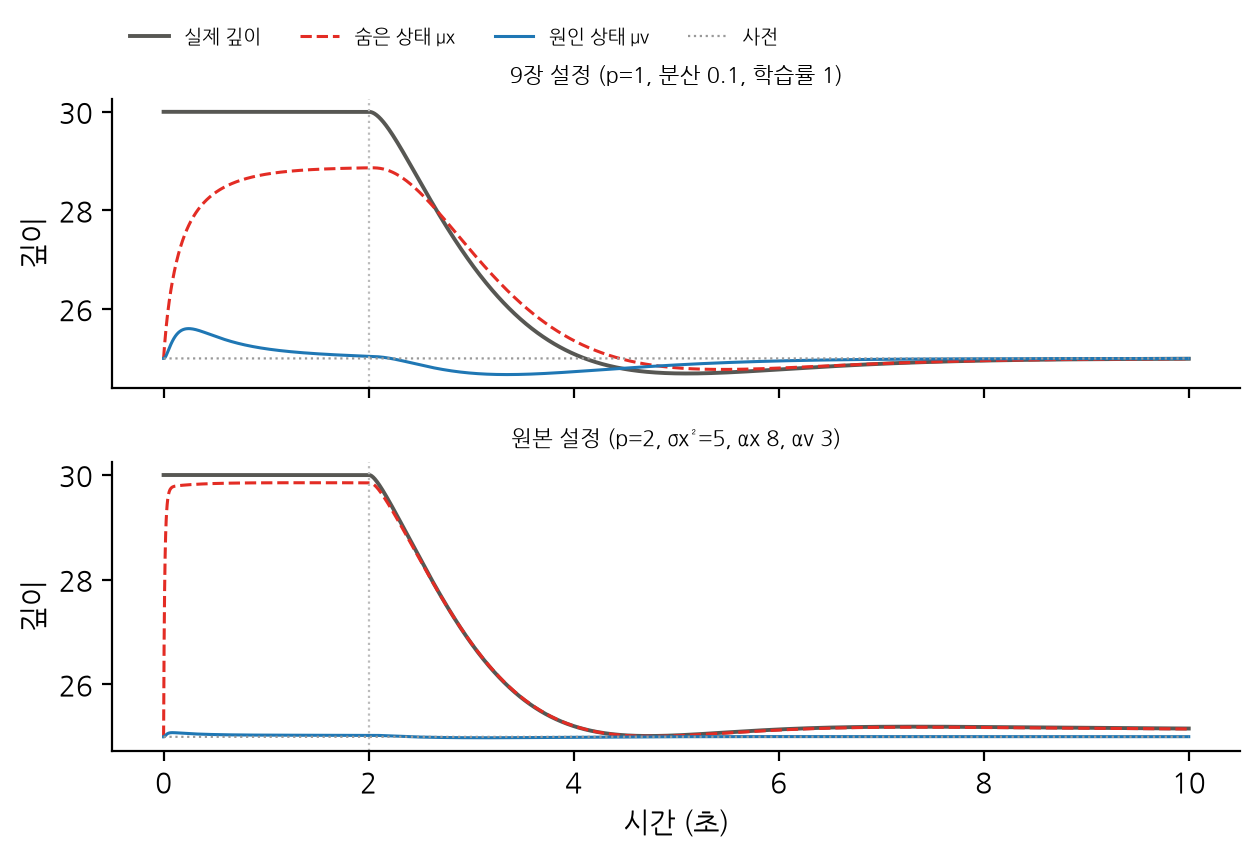

In [6]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.4))
for a_, (name, r) in zip(ax, r_unb.items()):
    a_.plot(r["t"], r["x"], color="#575753", lw=1.4, label="실제 깊이")
    a_.plot(r["t"], r["mx"], color="#E32C24", lw=1.1, ls="--", label="숨은 상태 μx")
    a_.plot(r["t"], r["mv"], color="#1f77b4", lw=1.1, label="원인 상태 μv")
    a_.plot(r["t"], r["prior"], color="#999999", lw=0.8, ls=":", label="사전")
    a_.axvline(2.0, color="#BBBBBB", lw=0.8, ls=":")
    a_.set_ylabel("깊이"); a_.set_title(name, fontsize=8)
ax[0].legend(frameon=False, fontsize=7, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.12))
ax[1].set_xlabel("시간 (초)")
fig.tight_layout(); plt.show()

## 5. 유색 잡음 속에서

생성 과정에 유색 잡음을 넣는다(매끄러움 1/2000). 원본처럼 분산 1 (감각·숨은 상태), 사전 0.1, αu = 1500 과 분산 0.1, αu = 150 을 비교한다. 행동 뒤 마지막 4 초의 깊이와 감각 수온의 흔들림, 그리고 숨은 상태 믿음의 흔들림을 본다.

In [7]:
print("경우                   도착(±1)   마지막 4초 깊이        감각 수온 표준편차   μx 표준편차")
for name, kw in [("분산 1, αu 1500", dict(s2_x=1.0, s2_y=1.0, a_u=1500)), ("분산 0.1, αu 150", dict(a_u=150))]:
    r = run(25.0, p=2, a_x=8, a_v=3, noise="smooth", **kw)
    tail = r["t"] > 6
    arr = arrival(r, tol=1.0)
    print(f"{name:18s}   {arr:6.2f}s   {r['x'][tail].mean():6.2f}±{r['x'][tail].std():.2f}        "
          f"{r['y'][tail].std():6.3f}             {r['mx'][tail].std():6.3f}")

경우                   도착(±1)   마지막 4초 깊이        감각 수온 표준편차   μx 표준편차


분산 1, αu 1500          7.29s    24.47±0.65         1.232              0.877


분산 0.1, αu 150         4.24s    24.74±0.39         0.497              0.578


## 6. 세 정밀도의 여덟 조합

감각(σy²), 사전(σv²), 숨은 상태(σx²) 의 분산을 각각 높은 정밀도 H(0.1) 와 낮은 정밀도 L(10) 로 둔 여덟 조합을 40 초 동안 돌린다. 행동은 0.2 초부터 켠다(αx = 8, αv = 3, αu = 150, p = 2). 행동 직전 μx 가 실제 깊이를, μv 가 사전을 얼마나 따르는지, 그리고 25 cm 에 도착하는지와 마지막 깊이를 본다.

In [8]:
H, L = 0.1, 10.0
print("감각 사전 숨은  | 0.2초: μx−실제  μv−사전 |  도착(±0.5)   40초 깊이")
table = {}
for sy, sv, sx in [(H, L, L), (H, L, H), (L, H, L), (L, H, H), (H, H, L), (H, H, H), (L, L, L), (L, L, H)]:
    r = run(25.0, T=40.0, s2_x=sx, s2_y=sy, s2_v=sv, a_x=8, a_v=3, a_u=150, p=2, t_act=0.2)
    k = at(r, 0.19)
    lab = "".join("H" if s == H else "L" for s in (sy, sv, sx))
    table[lab] = r
    arr = arrival(r)
    print(f" {lab[0]}    {lab[1]}    {lab[2]}   |   {r['mx'][k] - r['x'][k]:+7.3f}   {r['mv'][k] - 25:+7.3f} |  "
          f"{('못함' if np.isinf(arr) else f'{arr:5.1f}s'):>8s}   {r['x'][-1]:7.2f}")

감각 사전 숨은  | 0.2초: μx−실제  μv−사전 |  도착(±0.5)   40초 깊이


 H    L    L   |    -0.112    +0.323 |      2.6s     25.13


 H    L    H   |    -0.233    +1.627 |        못함     27.38


 L    H    L   |    -4.435    +0.005 |     25.2s     25.44


 L    H    H   |    -4.701    +0.015 |     17.8s     24.97


 H    H    L   |    -0.118    +0.041 |      4.1s     25.03


 H    H    H   |    -0.399    +0.119 |      2.5s     25.00


 L    L    L   |    -4.433    +0.022 |        못함     25.56


 L    L    H   |    -4.655    +0.100 |        못함     27.40


## 7. 움직이는 사전을 따라가기

Hydar 는 깊이 30 에 있고 사전도 30 이다. 3 초부터 5 초 사이에 사전이 가우스 꼴로 25 까지 올라갔다 돌아온다. 원인 상태가 사전을 따르도록 σv² 를 작게, 학습률을 크게 두고(원본의 최적화 설정: σx² = 0.1, σy² = 0.1, σv² = 0.1, αx = 3, αv = 8, αu = 1050, p = 2), 생성 모델의 시간 상수를 바꾼다. f = a(μx − μv) 에서 a = −1 과 a = −5 다.

In [9]:
t10 = timeline(10.0)
prior_bump = np.full(t10.size, 30.0)
prior_bump[600:1000] = 30 - 5 * gaussian(400, std=30)
r_b = run(prior_bump, x_init=30.0, s2_x=0.1, s2_y=0.1, s2_v=0.1, a_x=3, a_v=8, a_u=1050, p=2)
print("신호            최솟값    시각")
for name, key in [("사전", "prior"), ("원인 상태 μv", "mv"), ("숨은 상태 μx", "mx"), ("실제 깊이 x", "x")]:
    k = np.argmin(r_b[key])
    print(f"{name:12s}   {r_b[key][k]:6.2f}   {r_b['t'][k]:5.2f}s")
print()
print("생성 모델의 시간 상수를 줄이면(a = −5), 오일러 한계 때문에 학습률도 줄여야 한다")
print("a      αx    αv    실제 깊이 최솟값    추적 RMSE(3~6초)")
for a, ax_, av_ in [(-1.0, 3, 8), (-5.0, 3, 8), (-1.0, 0.5, 0.5), (-5.0, 0.5, 0.5)]:
    r = run(prior_bump, x_init=30.0, a_x=ax_, a_v=av_, a_u=1050, p=2, a=a)
    win = (r["t"] > 3) & (r["t"] < 6)
    with np.errstate(all="ignore"):
        rm = np.sqrt(np.mean((r["x"][win] - r["prior"][win])**2))
    print(f"{a:+.0f}    {ax_:4.1f}  {av_:4.1f}       {np.nanmin(r['x']) if np.isfinite(rm) else float('nan'):8.2f}          {rm:8.3f}")

신호            최솟값    시각
사전              25.00    4.00s
원인 상태 μv        25.19    4.01s
숨은 상태 μx        28.85    4.00s
실제 깊이 x         28.66    4.37s

생성 모델의 시간 상수를 줄이면(a = −5), 오일러 한계 때문에 학습률도 줄여야 한다
a      αx    αv    실제 깊이 최솟값    추적 RMSE(3~6초)


-1     3.0   8.0          28.66             1.414
-5     3.0   8.0            nan               nan
-1     0.5   0.5          28.99             1.558


-5     0.5   0.5          29.30             1.513


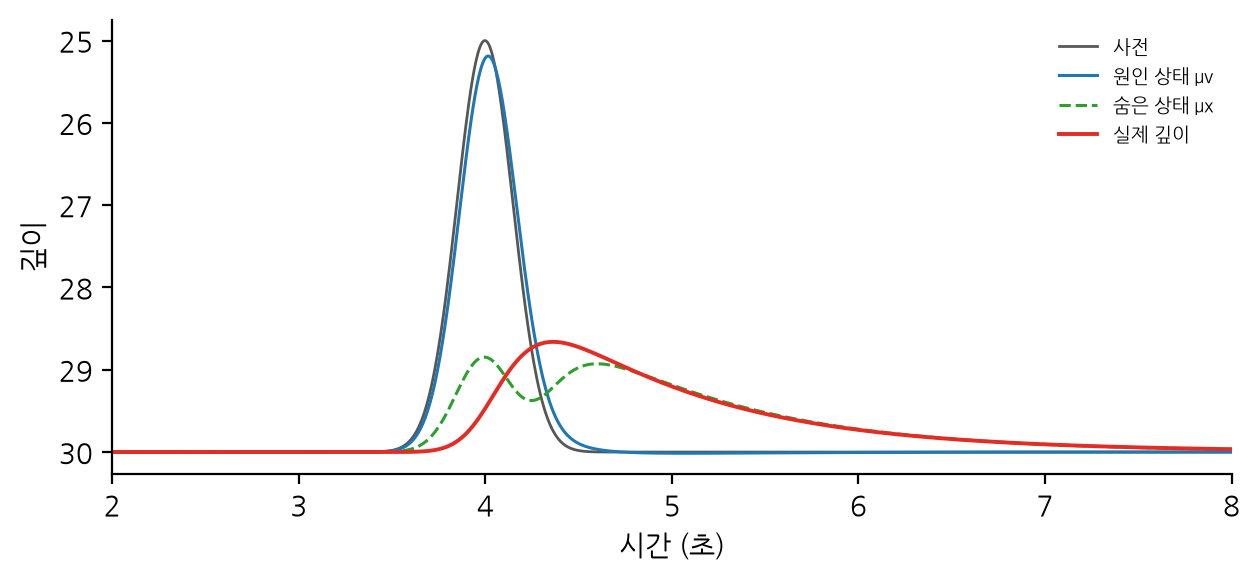

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 3.0))
ax.plot(t10, prior_bump, color="#575753", lw=1.0, label="사전")
ax.plot(t10, r_b["mv"], color="#1f77b4", lw=1.1, label="원인 상태 μv")
ax.plot(t10, r_b["mx"], color="#2ca02c", lw=1.1, ls="--", label="숨은 상태 μx")
ax.plot(t10, r_b["x"], color="#E32C24", lw=1.4, label="실제 깊이")
ax.invert_yaxis(); ax.set_xlim(2, 8)
ax.set_xlabel("시간 (초)"); ax.set_ylabel("깊이")
ax.legend(frameon=False, fontsize=7, loc="upper right")
fig.tight_layout(); plt.show()

## 결론

- 원인 상태를 추정하는 캡슐도 9장과 같이 행동해 25 cm 에 간다.
- 숨은 상태를 덜 믿고 감각과 사전을 믿으면, 숨은 상태는 실제 깊이를, 원인 상태는 사전을 가리킨다. 그래도 행동은 사전 쪽으로 간다. 믿음을 일부러 틀리게 두지 않아도 된다.
- 감각 정밀도는 숨은 상태를 감각 쪽으로, 사전 정밀도는 원인 상태를 사전 쪽으로 끈다. 사전을 믿지 않으면 행동이 목표로 가지 못한다.
- 움직이는 사전을 잘 따라가려면 생성 모델의 시간 상수가 사전의 변화보다 빨라야 한다.